# Étape 1 — Chargement et Analyse exploratoire des données (EDA)
## 1.1 -  Chargement de Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/student-mental-health.csv")

## 1.2 - comprendre la structure générale du jeu de données (types de données, dimensions, aperçus)

In [2]:
display(df.shape)

(2000, 17)

In [3]:
display(df.head())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

## 1.3 - Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes.

In [5]:
missing_values_count = df.isnull().sum()

mvc_percentage = (missing_values_count / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing values count" : missing_values_count,
    "missing values percentage" : mvc_percentage,
})

missing_df.sort_values(by="Missing values count" , ascending=False)

,Missing values count,missing values percentage
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90
Student_ID,0,0.00
Age,0,0.00
Screen_Time_Hours,0,0.00


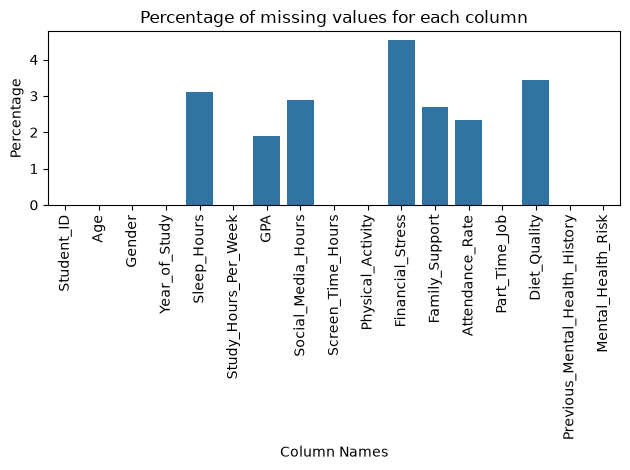

In [6]:
sns.barplot(x = missing_df.index , y= missing_df["missing values percentage"])

plt.xticks(rotation = 90)
plt.title("Percentage of missing values for each column")
plt.xlabel("Column Names")
plt.ylabel("Percentage")

plt.tight_layout()
plt.show()

In [7]:
print("Duplicated row: " , df.duplicated().sum())

Duplicated row:  0


In [8]:
GPA_check = df[
    (df["GPA"] < 0)
    | (df["GPA"] > 4)
]

print("ilogical cases:", len(GPA_check))

ilogical cases: 0


In [9]:
age_check = df[
    (df["Age"] < 16) | (df["Age"] > 30)
]

print("ilogical cases: ", len(age_check))

ilogical cases:  0


In [10]:
social_media_check = df[df["Social_Media_Hours"] > df["Screen_Time_Hours"]]

print("ilogical cases:", len(social_media_check))

display(df["Social_Media_Hours"].median())
display(social_media_check[["Social_Media_Hours","Screen_Time_Hours"]])


ilogical cases: 37


np.float64(6.0)

,Social_Media_Hours,Screen_Time_Hours
78,5.0,4.9
168,5.6,5.3
209,7.5,7.3
278,6.0,5.1
382,5.3,4.1
424,5.5,4.4
476,5.5,5.3
505,5.6,5.5
557,4.6,4.4
588,5.7,5.3


In [11]:
categorical_columns = ["Gender", "Physical_Activity", "Part_Time_Job", "Diet_Quality", "Previous_Mental_Health_History", "Mental_Health_Risk"]
numerical_columns = df.select_dtypes(include="number").columns

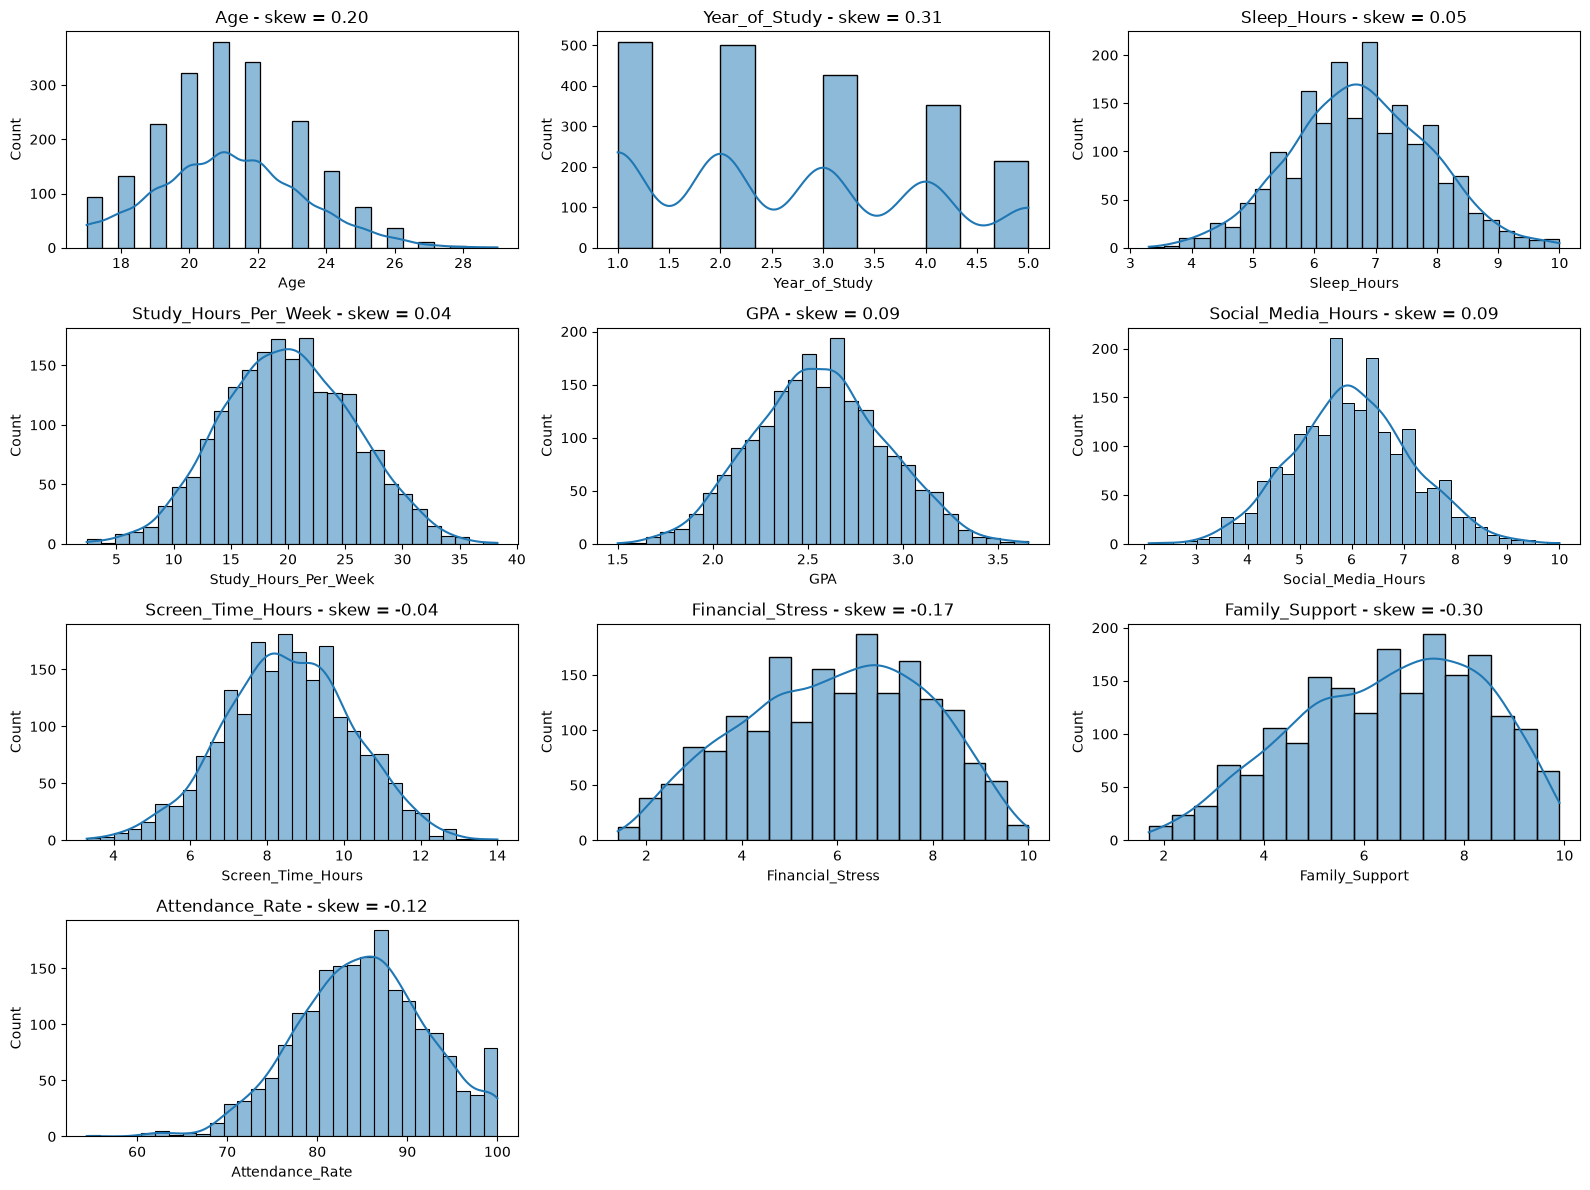

In [12]:
plt.figure(figsize=(16 , 12))

for i , column in enumerate(numerical_columns , 1):
    plt.subplot(4 , 3 , i)

    sns.histplot(data=df , x = column , kde = True)
    skewness = df[column].skew()
    plt.title(f"{column} - skew = {skewness:.2f}")

plt.tight_layout()
plt.show()

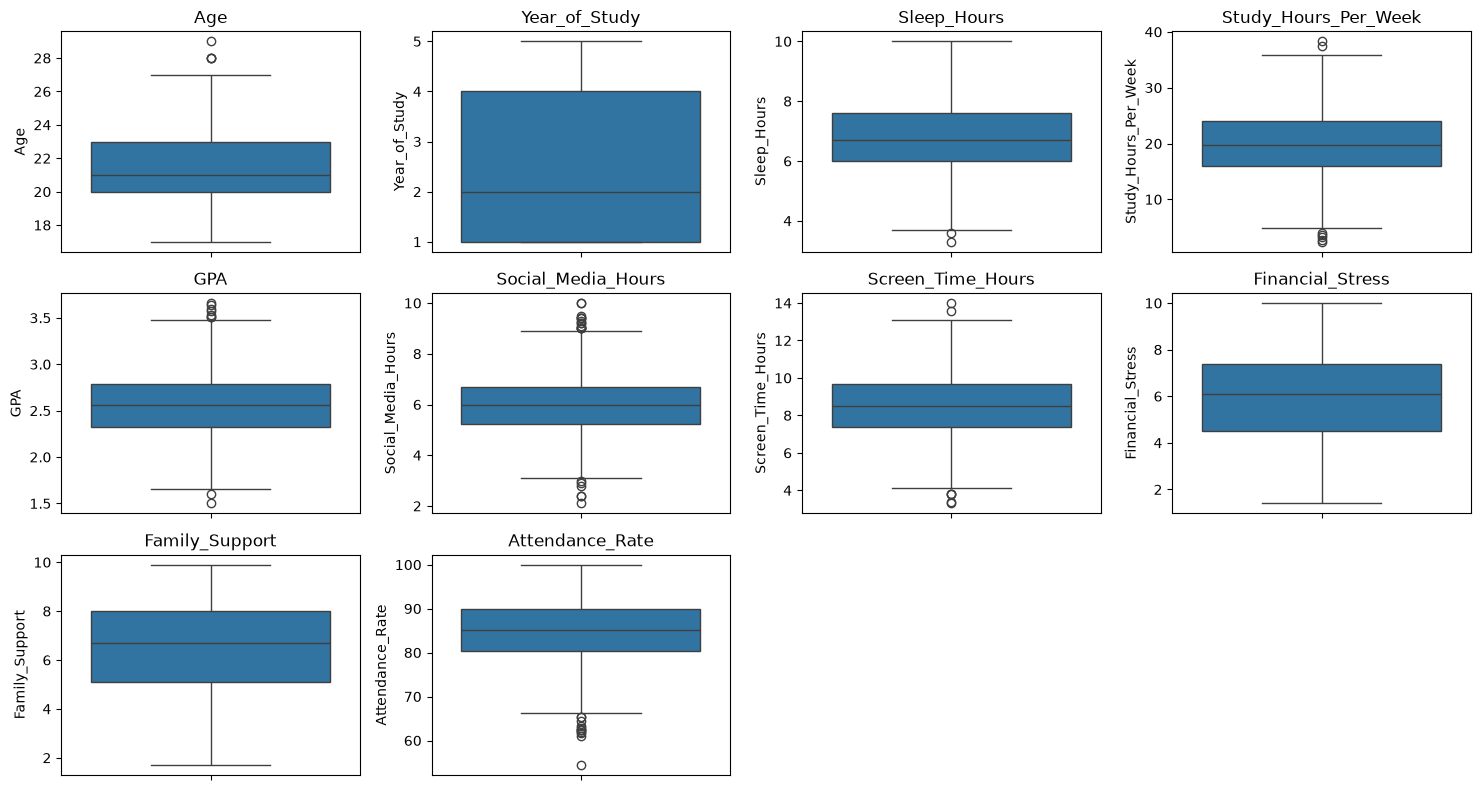

In [13]:
plt.figure(figsize=(15 , 8))

for i , column in enumerate(numerical_columns , 1):
    plt.subplot(3 , 4 , i)
    sns.boxplot(y = df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [14]:
print("unique values: ")
df.nunique().sort_values(ascending=False)

unique values: 


Student_ID                        2000
Attendance_Rate                    313
Study_Hours_Per_Week               284
GPA                                182
Screen_Time_Hours                   95
Financial_Stress                    87
Family_Support                      82
Social_Media_Hours                  71
Sleep_Hours                         66
Age                                 13
Year_of_Study                        5
Gender                               3
Physical_Activity                    3
Diet_Quality                         3
Mental_Health_Risk                   3
Part_Time_Job                        2
Previous_Mental_Health_History       2
dtype: int64

## 1.4 - Produire des statistiques descriptives.

In [15]:
display(df.describe())

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


## 1.5 - Étudier la distribution de la variable cible et l’éventuel déséquilibre des classes.

,Effectif,Proportion (%)
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


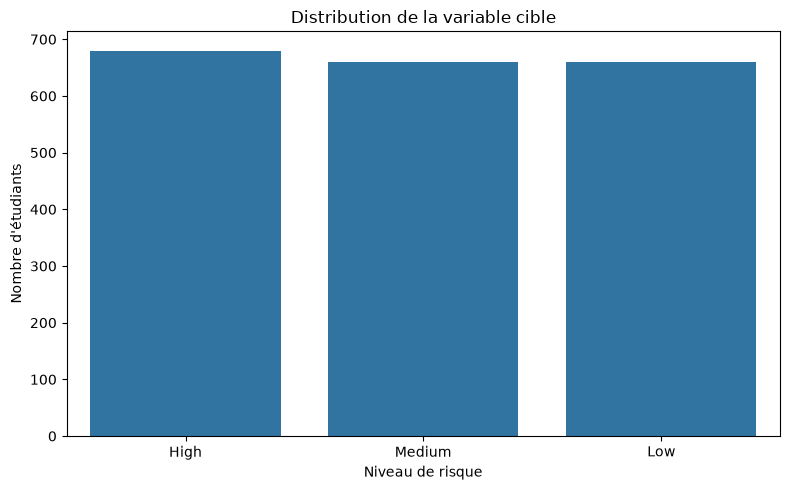

In [16]:
target_counts = df["Mental_Health_Risk"].value_counts()
target_props = df["Mental_Health_Risk"].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({"Effectif": target_counts, "Proportion (%)": target_props.round(2)})
display(target_summary)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="Mental_Health_Risk", order=target_counts.index)
plt.title("Distribution de la variable cible")
plt.xlabel("Niveau de risque")
plt.ylabel("Nombre d'étudiants")
plt.tight_layout()
plt.show()

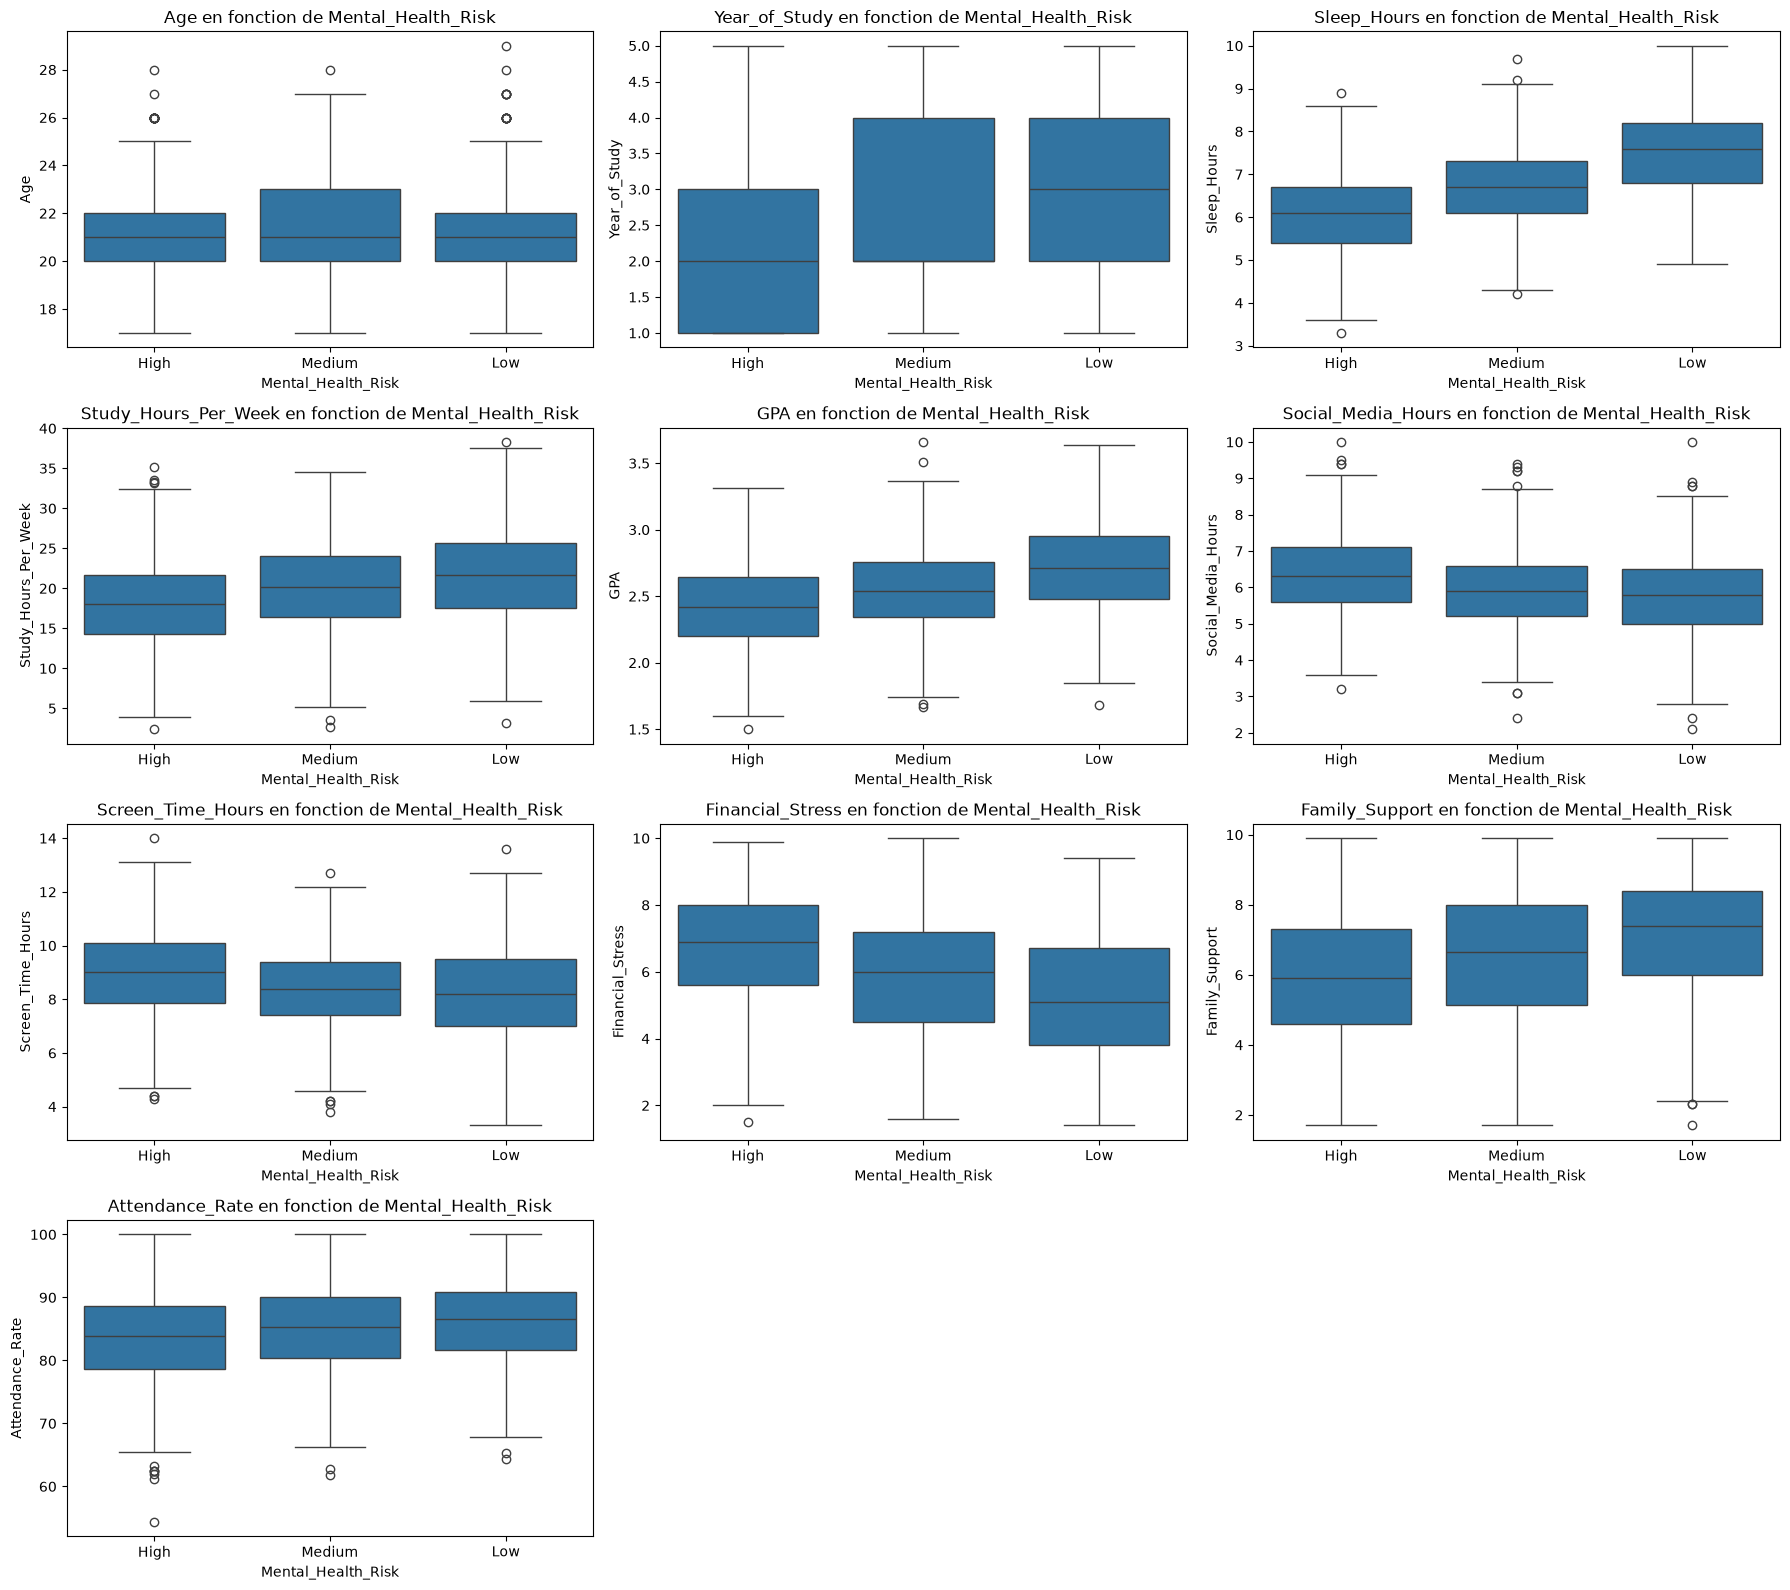

In [17]:
plt.figure(figsize=(18,16))
for i,col in enumerate(numerical_columns,1):
    plt.subplot(4 , 3 , i)
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col)
    plt.title(f"{col} en fonction de Mental_Health_Risk")
plt.tight_layout()
plt.show()

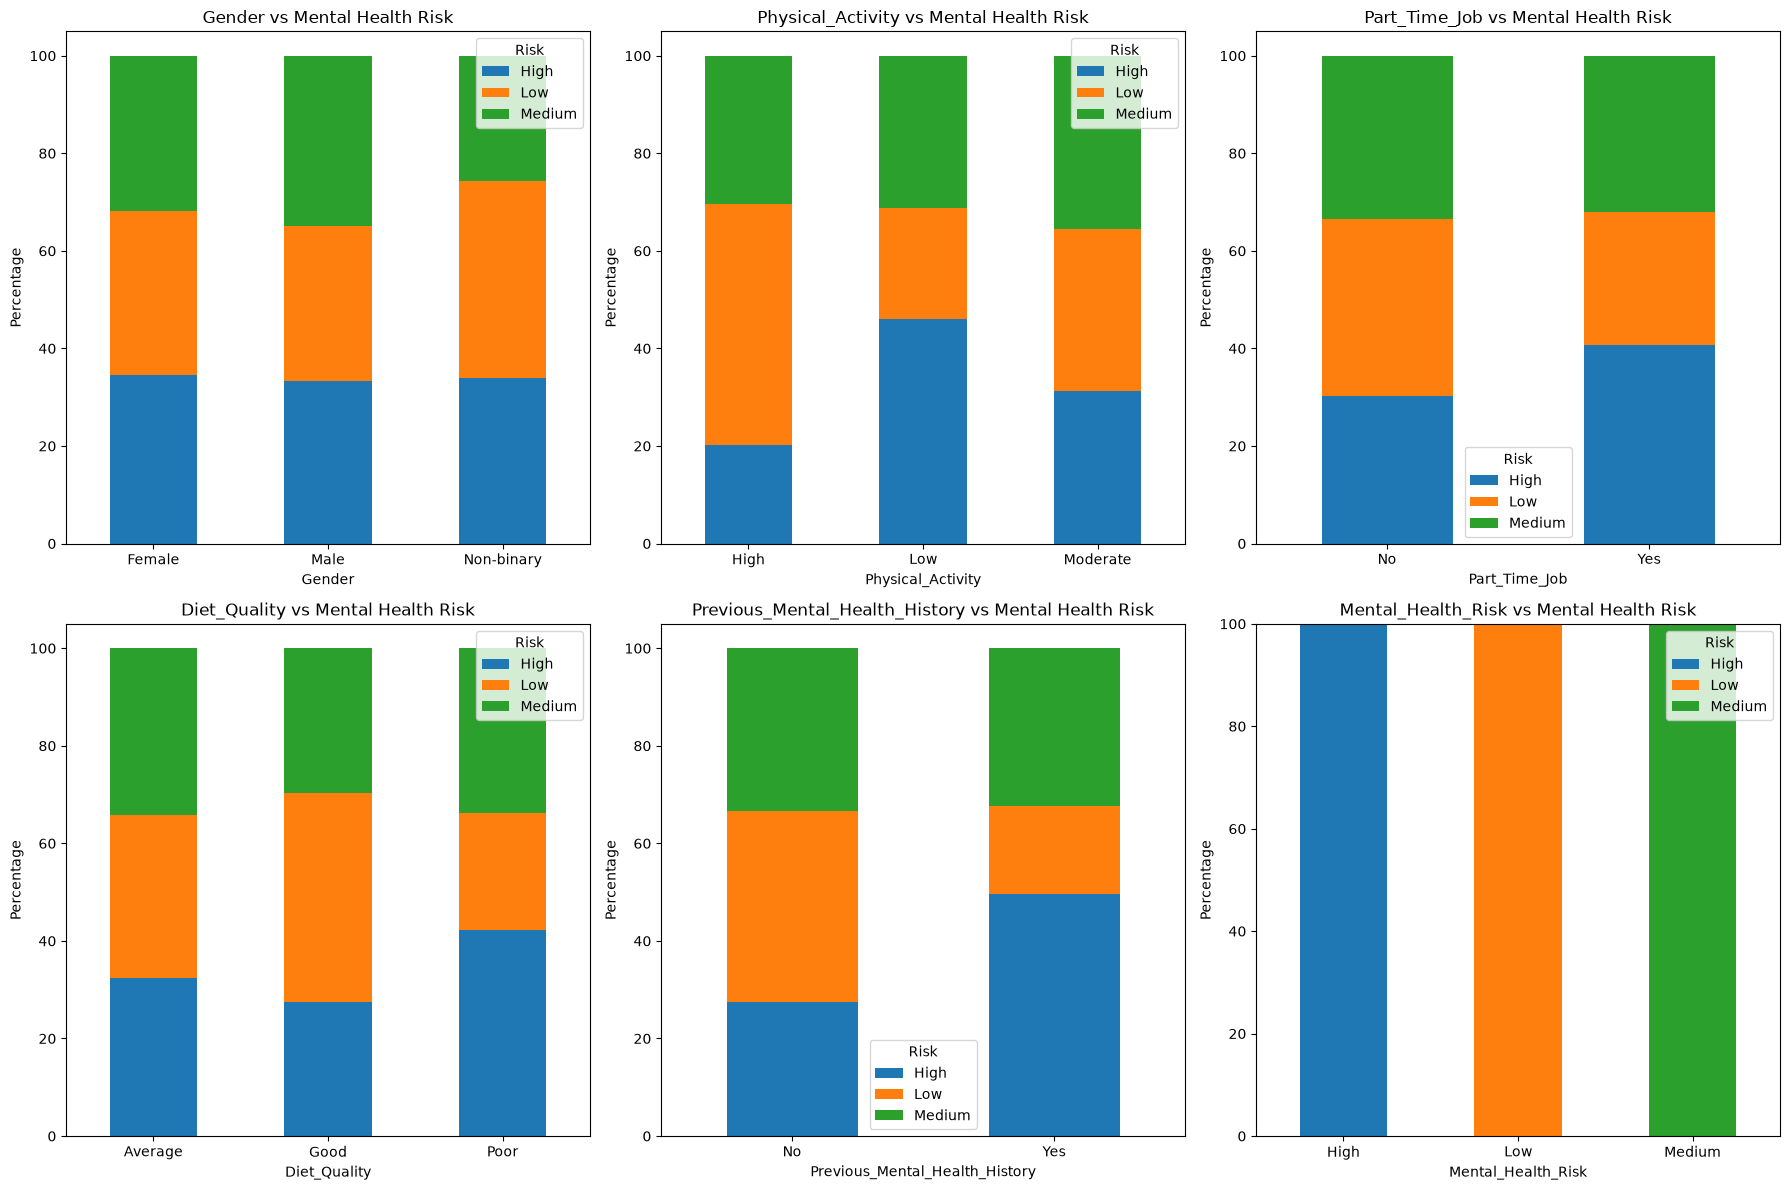

In [18]:
plt.figure(figsize = (18 , 12))

for i , column in enumerate(categorical_columns , 1):
    plt.subplot(2, 3, i)

    risk_distribution = pd.crosstab(
        df[column],
        df["Mental_Health_Risk"],
        normalize="index",
    ) * 100

    risk_distribution.plot(
        kind = "bar",
        stacked= True,
        ax = plt.gca()
    )

    plt.title(f"{column} vs Mental Health Risk")
    plt.xlabel(column)
    plt.ylabel("Percentage")
    plt.xticks(rotation=0)
    plt.legend(title="Risk")

plt.tight_layout()
plt.show()

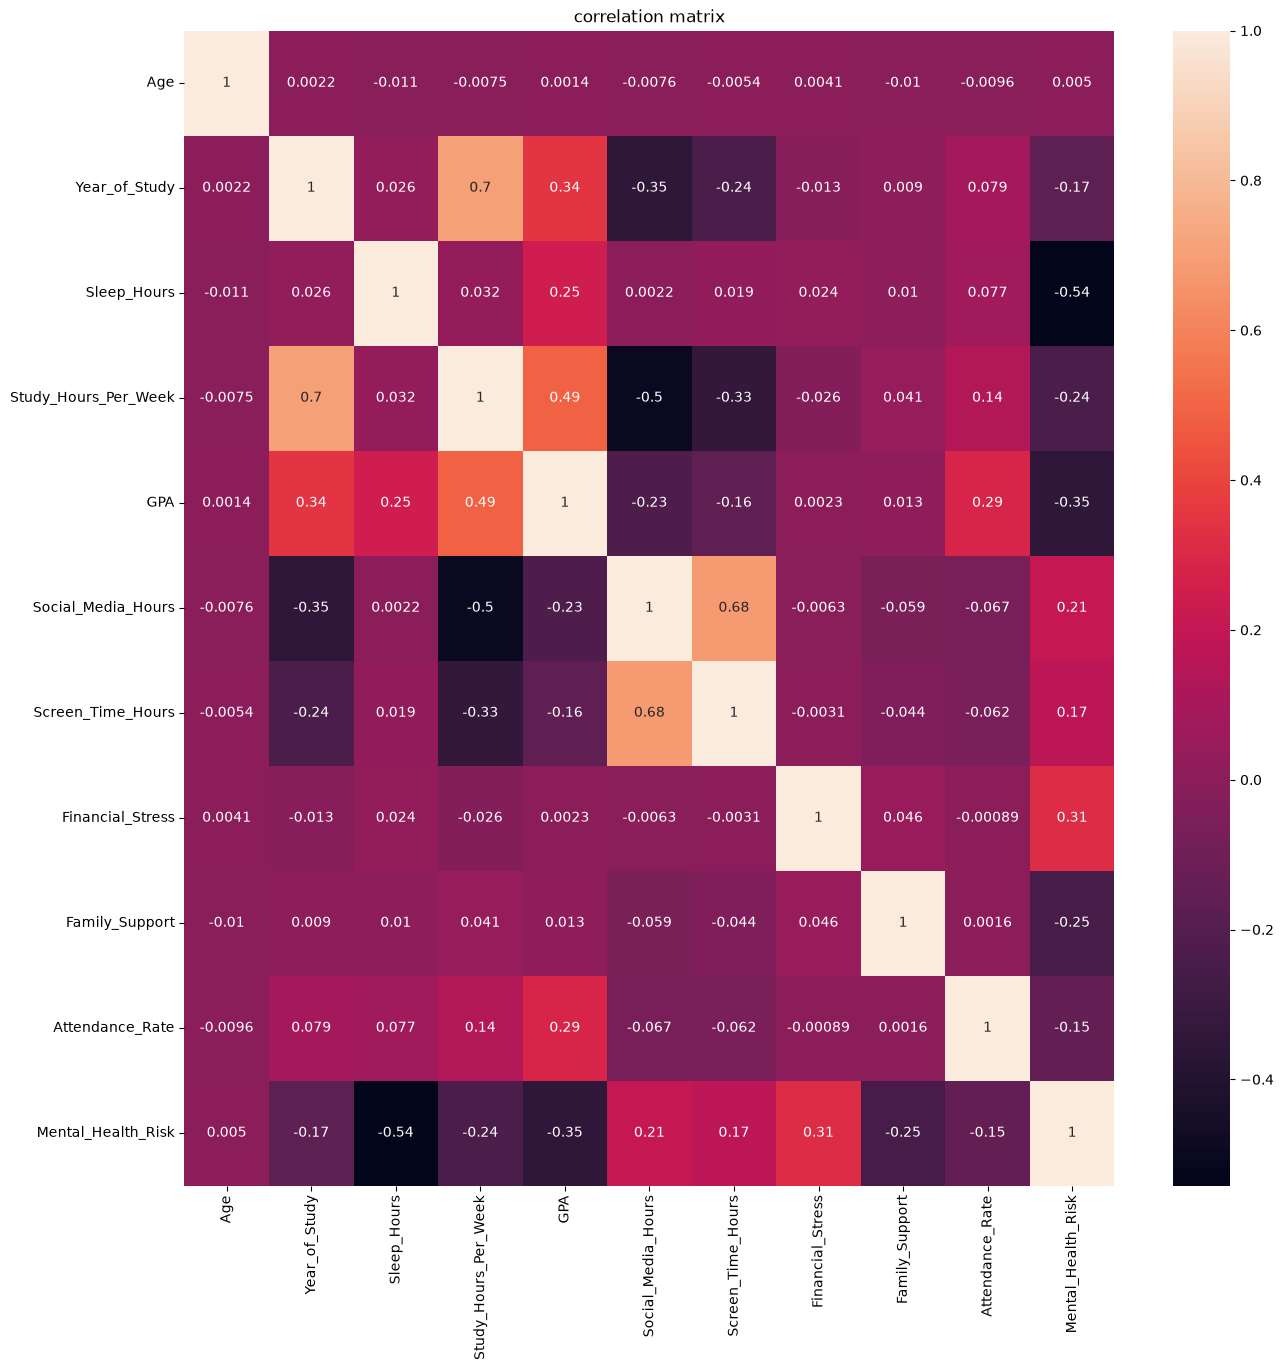

In [19]:
df_copy = df.copy()
df_copy["Mental_Health_Risk"] = df_copy["Mental_Health_Risk"].map({"Low":0, "Medium":1, "High":2}) 
corr_mat = df_copy.select_dtypes(include="number").corr()
plt.figure(figsize=(15,15))
sns.heatmap(corr_mat, annot=True)
plt.title("correlation matrix")
plt.show()

# Étape 2 — Transformation et préparation des données

## 2-0 corriger les inconsistensies.

In [20]:
df.loc[df['Screen_Time_Hours'] < df['Social_Media_Hours'], 'Screen_Time_Hours'] = df.loc[df['Screen_Time_Hours'] < df['Social_Media_Hours'], "Social_Media_Hours"]


## 2-1 Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).

In [21]:
target = df["Mental_Health_Risk"]
features = df.drop(columns=["Mental_Health_Risk","Student_ID"])

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features,target,test_size=0.2,random_state=42,stratify=target)

In [23]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((1600, 15), (1600,), (400, 15), (400,))

## 2-2 Traiter les valeurs manquantes en choisissant la méthode d’imputation la plus adaptée à la nature des données

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",drop="first")),
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1,categories=[["Low", "Moderate", "High"],["Poor", "Average", "Good"]])),
])

nominal_features = ["Gender","Part_Time_Job","Previous_Mental_Health_History"]
ordinal_features = ["Physical_Activity","Diet_Quality"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_columns),
        ("ord_cat", ordinal_pipeline, ordinal_features),
        ("nom_cat", nominal_pipeline, nominal_features),
    ]
)

## 2.3 - Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée (IQR, Z-score, etc.).

In [25]:
outlier_records = []

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outliers_pct = (outliers_count / len(df)) * 100
    
    outlier_records.append({
        "Variable": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Borne_Inf": round(lower_bound, 2),
        "Borne_Sup": round(upper_bound, 2),
        "Nb_Outliers": outliers_count,
        "Pourcentage (%)": round(outliers_pct, 2)
    })

df_outliers = pd.DataFrame(outlier_records).sort_values(by="Nb_Outliers", ascending=False).reset_index(drop=True)
display(df_outliers)

,Variable,Q1,Q3,IQR,Borne_Inf,Borne_Sup,Nb_Outliers,Pourcentage (%)
0,Social_Media_Hours,5.22,6.70,1.48,3.01,8.91,20,1.00
1,Attendance_Rate,80.30,90.00,9.70,65.75,104.55,12,0.60
2,GPA,2.32,2.79,0.47,1.61,3.50,9,0.45
3,Study_Hours_Per_Week,16.00,24.00,8.00,4.00,36.00,7,0.35
4,Screen_Time_Hours,7.40,9.70,2.30,3.95,13.15,7,0.35
5,Age,20.00,23.00,3.00,15.50,27.50,4,0.20
6,Sleep_Hours,6.00,7.60,1.60,3.60,10.00,2,0.10
7,Year_of_Study,1.00,4.00,3.00,-3.50,8.50,0,0.00
8,Financial_Stress,4.50,7.40,2.90,0.15,11.75,0,0.00
9,Family_Support,5.10,8.00,2.90,0.75,12.35,0,0.00


## 2.4 - Encoder les variables catégorielles afin de les convertir en valeurs numériques

### Deja fait en 2.2 

## 2.5 - Gérer le déséquilibre des classes avec des techniques de sur-échantillonnage ou sous-échantillonnage (Smote), si nécessaire. 

N'est pas necessaire: les classes sont en equilibre

## 2.6 - Normaliser ou standardiser les variables numériques afin de les mettre à la même échelle.

### Deja fait en 2.2 

## 2.7 - Regrouper les transformations dans un pipeline afin d’éviter le data leakage. 

### Deja fait en 2.2 

In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nMissing values in training:", np.isnan(X_train_processed).sum())

print("Missing values in testing:", np.isnan(X_test_processed).sum())

Training shape: (1600, 16)
Testing shape: (400, 16)

Missing values in training: 0
Missing values in testing: 0


# Étape 3 — Entraînement et comparaison des modèles

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

## 3.1 - Entraîner au moins 3 modèles de classification.

In [28]:
pipelines = {
    "Logistic Regression": Pipeline(steps=[
        ('pre_processing',preprocessor),
        ('classifier',LogisticRegression(max_iter=1000,random_state=42)),
        ]),
    "Random Forest Classifier": Pipeline(steps=[
        ('pre_processing',preprocessor),
        ('classifier',RandomForestClassifier(max_depth=200,random_state=42)),
        ]),
    "K Neighbors Classifier": Pipeline(steps=[
        ('pre_processing',preprocessor),
        ('classifier',KNeighborsClassifier()),
        ]),
    }

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay


,Name,accuracy,precision,recall,f1,confusion matrix
0,Logistic Regression,0.7575,0.757536,0.7575,0.757510,"[[108, 23, 1], [23, 84, 25], [0, 25, 111]]"
1,Random Forest Classifier,0.7150,0.713102,0.7150,0.713977,"[[104, 26, 2], [28, 75, 29], [2, 27, 107]]"
2,K Neighbors Classifier,0.5875,0.577930,0.5875,0.581657,"[[92, 30, 10], [41, 49, 42], [6, 36, 94]]"


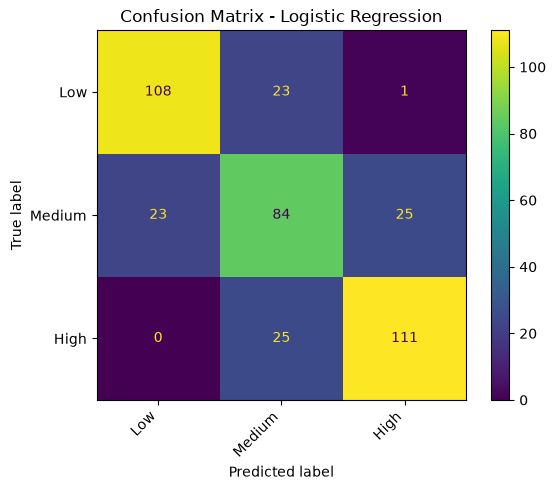

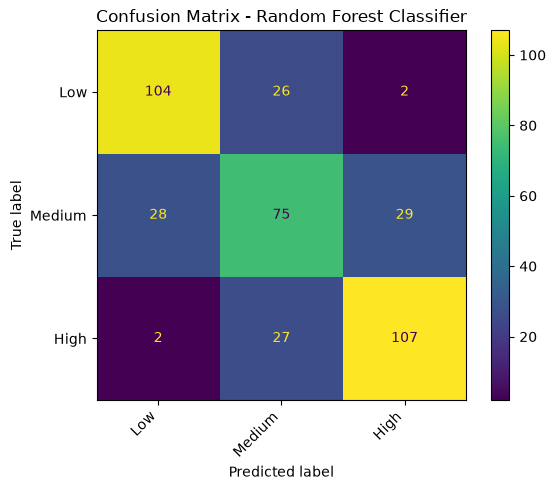

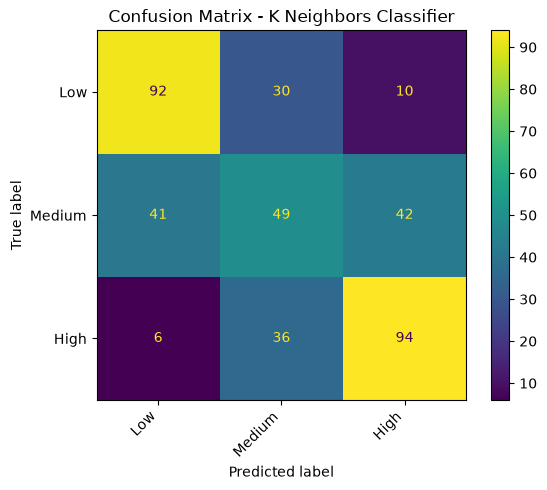

In [30]:
results = {
    "Name":[],
    "accuracy":[],
    "precision":[],
    "recall":[],
    "f1":[],
    "confusion matrix":[],
    }
for name,pipeline in pipelines.items():
    pipeline.fit(X_train,y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test , y_pred)
    precision = precision_score(y_test , y_pred , average="weighted")
    recall = recall_score(y_test , y_pred, average="weighted")
    f1 = f1_score(y_test , y_pred , average="weighted")
    cm = confusion_matrix(y_test , y_pred,labels=['Low', 'Medium', 'High'])

    results["Name"].append(name)
    results["accuracy"].append(accuracy)
    results["precision"].append(precision)
    results["recall"].append(recall)
    results["f1"].append(f1)
    results["confusion matrix"].append(cm)

result_df = pd.DataFrame(results)

display(result_df)

for name, cm in zip(result_df["Name"], result_df["confusion matrix"]):
    disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels=['Low', 'Medium', 'High']

    )
    disp.plot()
    plt.xticks(rotation=45, ha='right')
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

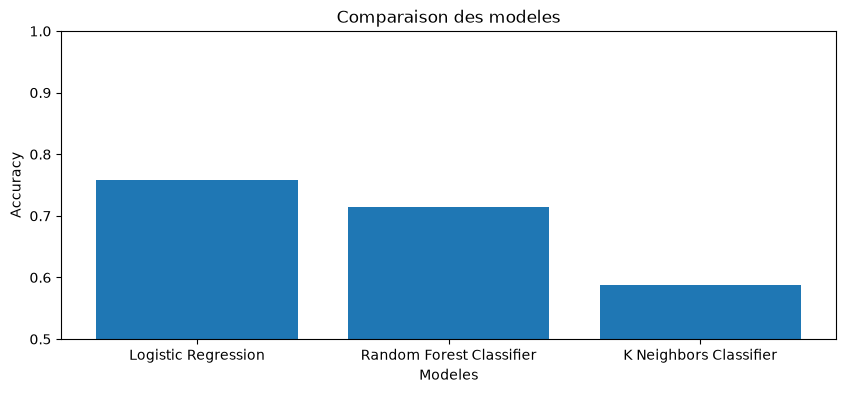

In [31]:
plt.figure(figsize = (10 , 4))

plt.bar(result_df["Name"] , result_df["accuracy"])
plt.title("Comparaison des modeles")
plt.xlabel("Modeles")
plt.ylabel("Accuracy")
plt.ylim(0.50, 1)

plt.show()

# Étape 4 — Optimisation et évaluation

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [33]:
grid_params = {
    "Logistic Regression": (
        Pipeline(
            steps=[
                ("pre_processing", preprocessor),
                ("classifier", LogisticRegression(max_iter=1000,random_state=42)),
            ]
        ),
        [
            {
                "classifier__C": np.logspace(-3, 3, 7),
                "classifier__solver": ["saga"],
            },
            {
                "classifier__C": np.logspace(-3, 3, 7),
                "classifier__solver": ["lbfgs", "newton-cg"],
            },
            {
                "classifier__C": np.logspace(-3, 3, 7),
                "classifier__solver": ["saga"],
                "classifier__l1_ratio": np.linspace(0, 1, 5),
            },
        ],
    ),
    "Random Forest Classifier": (
        Pipeline(
            steps=[
                ("pre_processing", preprocessor),
                ("classifier", RandomForestClassifier(max_depth=200,random_state=42)),
            ]
        ),
        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [None, 10, 20, 30],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__min_samples_leaf": [1, 2, 4],
            "classifier__max_features": ["sqrt", "log2"],
            "classifier__criterion": ["gini", "entropy"],
        },
    ),
    "K Nearest Neighbors Classifier": (
        Pipeline(
            steps=[
                ("pre_processing", preprocessor),
                ("classifier", KNeighborsClassifier()),
            ]
        ),
        {
            "classifier__n_neighbors": np.arange(1, 25, 2),
            "classifier__weights": ["uniform", "distance"],
            "classifier__metric": ["euclidean", "manhattan", "minkowski"],
            "classifier__p": [1, 2],
        },
    ),
}

In [34]:
best_overall_model = None
best_overall_score = 0
best_model_name = ""

op_results = []

for name, (pipeline, param_grid) in grid_params.items():

    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring='f1_weighted',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)


    op_results.append({
        "name":name,
        "best_params":grid_search.best_params_,
        "score":grid_search.best_score_
        })

    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_model_name = name


In [35]:
res_df = pd.DataFrame(op_results)
display(res_df)

,name,best_params,score
0,Logistic Regression,"{'classifier__C': 1.0, 'classifier__solver': '...",0.748562
1,Random Forest Classifier,"{'classifier__criterion': 'entropy', 'classifi...",0.690637
2,K Nearest Neighbors Classifier,"{'classifier__metric': 'manhattan', 'classifie...",0.655805


In [36]:
y_pred = best_overall_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")


print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.76
Precision: 0.7596061511229117
Recall: 0.76
F1-score: 0.7597812994365962


In [37]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
    )
)

              precision    recall  f1-score   support

         Low       0.82      0.82      0.82       132
      Medium       0.64      0.64      0.64       132
        High       0.81      0.82      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



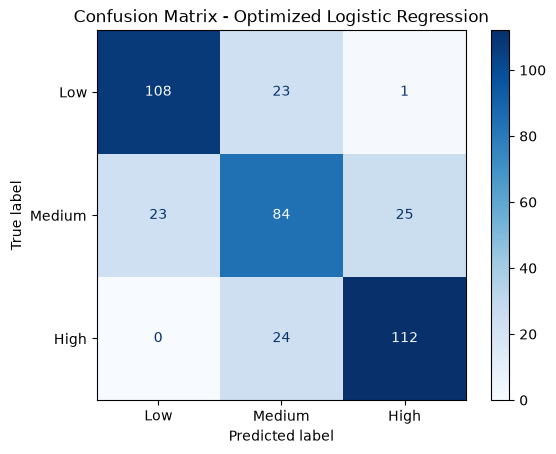

In [38]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"],
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Optimized Logistic Regression")
plt.show()

In [39]:
import joblib
joblib.dump(best_overall_model,"../models/best_model.joblib")

['../models/best_model.joblib']

In [42]:
display(np.arange(1, 25, 2))

array([ 1,  3,  5,  7,  9, 11, 13, 15, 17, 19, 21, 23])